# Singly linked list data structure

## Definition of the singly linked list data structure

In [22]:
sealed class List<out A> // Sealed definition of the data type

object Nil: List<Nothing>() // Nil implementation of List

data class Cons<out A>(val head: A, val tail: List<A>): List<A>() // Cons implementation

In [23]:
val lst1: List<Double> = Nil
val lst2: List<Int> = Cons(1, Nil)
val lst3: List<String> = Cons("a", Cons("b", Nil))

In [24]:
lst2

Cons(head=1, tail=Line_24_jupyter$Nil@4133b087)

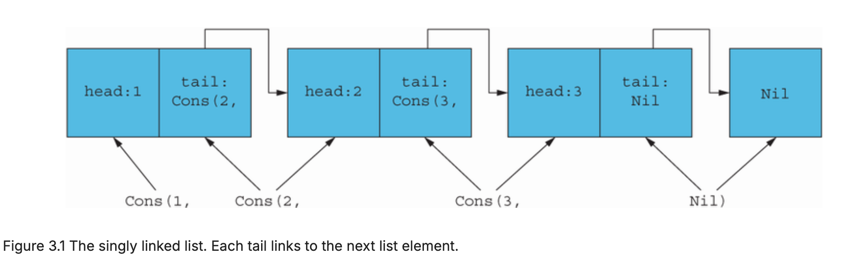

In [41]:
sealed class List<out A> {
    companion object {
        fun <A> of(vararg aa: A): List<A> {
            val tail = aa.sliceArray(1 until aa.size)
            return if (aa.isEmpty()) Nil else Cons(aa[0], of(*tail))
        }
    }
}

object Nil: List<Nothing>()

data class Cons<out A>(val head: A, val tail: List<A>): List<A>()

In [7]:
List.of(1,2)

Cons(head=1, tail=Cons(head=2, tail=Line_8_jupyter$Nil@7797260c))

In [8]:
List.of("a","b","c","d","e","f")

Cons(head=a, tail=Cons(head=b, tail=Cons(head=c, tail=Cons(head=d, tail=Cons(head=e, tail=Cons(head=f, tail=Line_8_jupyter$Nil@7797260c))))))

In [44]:
List.of()


org.jetbrains.kotlinx.jupyter.exceptions.ReplCompilerException: at Cell In[44], line 1, column 6: Not enough information to infer type variable A

An empty list still needs an element type. When calling `List.of()` without arguments, Kotlin has no elements which to infer `A`.

### Solutions

In [50]:
//list.of()

List.of<Int>() // Specify the type argument

val empty: List<Int> = List.of() // Provide the expected type

val numbers = List.of(1,2, 3) // with elements, Kotlin infers the type

In [42]:
val empty = List.of<Int>()


## Variance
* In the declaration class `List<out A>`, the `out` in front of the type parameter `A` is a variance annotation signaling that `A` is a covariant or “positive” parameter of List.

* This means, for instance, that List<Dog> is considered a subtype of List<Animal>, assuming Dog is a subtype of Animal.

* More generally, for all types X and Y, if X is a subtype of Y, then List<X> is a subtype of List<Y>.

In [53]:
abstract class Pet(var name: String)
class Cat(name: String) : Pet(name)
class Dog(name: String) : Pet(name)
class Fish(name: String) : Pet(name)

Let's use our `List<out A>` definition


In [54]:
val dogs: List<Dog> = List.of(Dog("Luna"), Dog("Max"))
// Dog is a subtype of Pet.
// Therefore, List<Dog> is a subtype of List<Pet>.
val pets: List<Pet> = dogs // Compiles because of `out A`!
println(pets === dogs) // true — the same list

true


### The "when" construct for matching by type

* For our purposes, the most helpful approach to matching `is` by type.
* The is keyword is used to match each logic branch by its concrete type


In [59]:
val ints = List.of(1, 2, 3, 4) // Declares an abstract list

fun sum(xs: List<Int>): Int =
    when (xs) {
        is Nil -> 0
        is Cons -> xs.head + sum(xs.tail)
    }

org.jetbrains.kotlinx.jupyter.exceptions.ReplCompilerException: at Cell In[59], line 4, column 5: 'when' expression must be exhaustive, add necessary 'else' branch

>Because our `List` is sealed and its only subtypes are `Nil` and `Cons`, handling both cases makes the when **expression exhaustive**.

>However, the `Kotlin notebook` kernel may still report an exhaustiveness error and require an else branch. In a regular Kotlin source file (`.kt`), this code should compile without else, as described in the Kotlin documentation.

In [64]:
val ints = List.of(1, 2, 3, 4) // Declares an abstract list

fun sum(xs: List<Int>): Int =
    when (xs) {
        is Nil -> 0 // Matches a Nil implementation
        is Cons -> xs.head + sum(xs.tail) // Smartcast a Cons implementation
        else -> error("Unexpected List subtype")

    }
sum(ints)

10

In [67]:
val ints = List.of(1, 2, 3, 4) // Declares an abstract list
fun product(xs: List<Int>): Int =
    when (xs) {
        is Nil -> 0
        is Cons -> xs.head + product(xs.tail)
        else -> error("Unexpected List subtype")

    }
sum(ints)

10

### Using foldRight as a generalization of `product` and `sum`

In [105]:
val ints = List.of(1, 2, 3, 4) // Declares an abstract list
val dbs = List.of(1.0, 2.0, 3.0, 4.0)

fun <A, B> foldRight(xs: List<A>, z: B, f:(A,B) -> B) : B =
    when (xs) {
        is Nil -> z
        is Cons -> f(xs.head, foldRight(xs.tail, z, f))
        else -> error("Unexpected List subtype")
    }

fun sum2(ints: List<Int>): Int =
    foldRight(ints, 0, { a, b -> a + b })

fun product2(dbs: List<Double>): Double =
    foldRight(dbs, 1.0, { a, b -> a * b })

sum2(ints)


10

In [106]:
product2(dbs)

24.0

### Data sharing in a singly linked list due to common underlying data structures

 The functions we will write in the exercises can be written two ways; either way is perfectly acceptable. The first approach is to place the functions inside the List companion object as we did for sum and product in the example.

In [111]:
sealed class List<out A> {
    companion object {
        fun <A> of(vararg aa: A): List<A> {
            val tail = aa.sliceArray(1 until aa.size)
            return if (aa.isEmpty()) Nil else Cons(aa[0], of(*tail))
        }

        fun <A, B> foldRight(
            xs: List<A>,
            z: B,
            f: (A, B) -> B
        ): B =
            when (xs) {
                is Nil -> z
                is Cons -> f(xs.head, foldRight(xs.tail, z, f))
                else -> error("Unexpected List subtype")
            }
        fun sum(ints: List<Int>): Int =
            foldRight(ints, 0) { a, b -> a + b }
        fun product(dbs: List<Double>): Double =
            foldRight(dbs, 1.0) { a, b -> a * b }
    }
}

object Nil: List<Nothing>()

data class Cons<out A>(val head: A, val tail: List<A>): List<A>()

In this apporach, the method take the list it is action on as its first argument

In [112]:
val xs = List.of(1, 2, 3, 4)
List.sum(xs)

10

In [115]:
val xs  = List.of(1.0, 2.0, 3.0, 4.0)
List.product(xs)

24.0

The other approach involves using extension methods like those introduced in the previous lecture. Doing so adds behavior to the list type itself, so we can operate on it in the following way:

In [116]:
sealed class List<out A> {
    companion object {
        fun <A> of(vararg aa: A): List<A> {
            val tail = aa.sliceArray(1 until aa.size)
            return if (aa.isEmpty()) Nil else Cons(aa[0], of(*tail))
        }
    }
}

object Nil: List<Nothing>()

data class Cons<out A>(val head: A, val tail: List<A>): List<A>()

In [123]:
fun <A, B> List<A>.foldRight(z: B, f: (A, B) -> B): B =
    when (this) {
        is Nil -> z
        is Cons -> f(head, tail.foldRight(z, f))
        else -> error("Unexpected List subtype")
    }

fun List<Int>.sum(): Int =
    foldRight(0) { a, b -> a + b }

fun List<Double>.product(): Double =
    foldRight(1.0) { a, b -> a * b }

In [121]:
val xs = List.of(1, 2, 3, 4)
xs.sum()

10

In [124]:
val xs  = List.of(1.0, 2.0, 3.0, 4.0)
xs.product()

24.0

### Exercise: tail

Implement the function tail for removing the first element of a List. Note that the function takes constant time. What different choices can you make in your implementation if the List is Nil? We’ll return to this question in the next chapter.

```Kotlin
fun <A> tail(xs: List<A>): List<A> =

    SOLUTION_HERE()
```

In [130]:
fun <A> tail(xs: List<A>): List<A> =
    when (xs) {
        is Cons -> xs.tail
        is Nil ->
            throw IllegalStateException("Nil cannot have a `tail`")
        else -> error("Unexpected List subtype")
    }

val xs = List.of(1, 2, 3, 4)
tail(xs)


Cons(head=2, tail=Cons(head=3, tail=Cons(head=4, tail=Line_118_jupyter$Nil@30335ba6)))

In [127]:
fun <A> List<A>.tail(): List<A> =
    when (this) {
        is Cons -> this.tail
        is Nil -> throw IllegalStateException("Nil cannot have a `tail`")
        else -> error("Unexpected List subtype") // Notebook compatibility
    }

In [131]:
val xs = List.of(1, 2, 3, 4)
xs.tail()


Cons(head=2, tail=Cons(head=3, tail=Cons(head=4, tail=Line_118_jupyter$Nil@30335ba6)))

Using the same idea as in the previous exercise, implement the function setHead for replacing the first element of a List with a different value.

``` Kotlin
fun <A> setHead(xs: List<A>, x: A): List<A> =

    SOLUTION_HERE()
```

In [133]:
fun <A> setHead(xs: List<A>, x: A): List<A> =
    when (xs) {
        is Nil ->
            throw IllegalStateException(
                "Cannot replace `head` of a Nil list"
            )
        is Cons -> Cons(x, xs.tail)
        else -> error("Unexpected List subtype")
    }

val xs = List.of(1, 2, 3, 4)
setHead(xs,0)

Cons(head=0, tail=Cons(head=2, tail=Cons(head=3, tail=Cons(head=4, tail=Line_118_jupyter$Nil@30335ba6))))

In [136]:
fun <A> List<A>.setHead(x: A): List<A> =
    when (this) {
        is Nil ->
            throw IllegalStateException(
                "Cannot replace `head` of a Nil list"
            )
        is Cons -> Cons(x, this.tail)
        else -> error("Unexpected List subtype")
    }

In [137]:
val xs = List.of(1, 2, 3, 4)
xs.setHead(0)

Cons(head=0, tail=Cons(head=2, tail=Cons(head=3, tail=Cons(head=4, tail=Line_118_jupyter$Nil@30335ba6))))

### The efficiency of data sharing

Data sharing often lets us implement operations more efficiently due to the immutability of the underlying data structures that we are dealing with. Let’s look at a few examples.

### Drop
Generalize tail to the function drop, which removes the first n elements from a list. Note that this function takes time proportional only to the number of elements being dropped—you don’t need to make a copy of the entire List.

``` Kotlin

fun <A> drop(l: List<A>, n: Int): List<A> =

    SOLUTION_HERE()

```

In [142]:
tailrec fun <A> drop(l: List<A>, n: Int): List<A> =
    if (n == 0) l
    else when (l) {
        is Cons -> drop(l.tail, n - 1)
        is Nil -> throw IllegalStateException(
            "Cannot drop more elements than in list"
        )
        else -> error("Unexpected List subtype")
    }

val xs = List.of(1, 2, 3, 4)
drop(xs, 0)

Cons(head=1, tail=Cons(head=2, tail=Cons(head=3, tail=Cons(head=4, tail=Line_118_jupyter$Nil@30335ba6))))

In [143]:
drop(xs, 1)

Cons(head=2, tail=Cons(head=3, tail=Cons(head=4, tail=Line_118_jupyter$Nil@30335ba6)))

In [144]:
tailrec fun <A> List<A>.drop(n: Int): List<A> =
    if (n == 0) this
    else when (this) {
        is Cons -> this.tail.drop(n - 1)
        is Nil -> throw IllegalStateException(
            "Cannot drop more elements than in list"
        )
        else -> error("Unexpected List subtype")
    }

In [147]:
val numbers = List.of(1, 2, 3, 4, 5)
val remaining = numbers.drop(2)
remaining

Cons(head=3, tail=Cons(head=4, tail=Cons(head=5, tail=Line_118_jupyter$Nil@30335ba6)))

#### dropWhile
Removes elements from the List prefix as long as they match a predicate.

```Kotlin
fun <A> dropWhile(l: List<A>, f: (A) -> Boolean): List<A> =

    SOLUTION_HERE()

```

In [149]:
tailrec fun <A> dropWhile(l: List<A>, f: (A) -> Boolean): List<A> =
    when (l) {
        is Cons ->
            if (f(l.head)) dropWhile(l.tail, f) else l
        is Nil -> l
        else -> error("Unexpected List subtype")
    }

In [153]:
val numbers = List.of(2, 4, 1, 6, 3, 8)
dropWhile(numbers, {it < 6})

Cons(head=6, tail=Cons(head=3, tail=Cons(head=8, tail=Line_118_jupyter$Nil@30335ba6)))

In [155]:
fun <A> append(a1: List<A>, a2: List<A>): List<A> =
    when (a1) {
        is Nil -> a2
        is Cons -> Cons(a1.head, append(a1.tail, a2))
        else -> error("Unexpected List subtype")
    }

val xs = List.of(2, 4, 1, 6, 3, 8)
val ys = List.of(9,10)
append(xs, ys)

Cons(head=2, tail=Cons(head=4, tail=Cons(head=1, tail=Cons(head=6, tail=Cons(head=3, tail=Cons(head=8, tail=Cons(head=9, tail=Cons(head=10, tail=Line_118_jupyter$Nil@30335ba6))))))))

### Length
Compute the length of a list using foldRight

In [158]:
fun <A> List<A>.length(): Int =
    foldRight(0) { _, acc -> 1 + acc }

val xs = List.of(2, 4, 1, 6, 3, 8)
xs.length()

6

# Functional List

In [159]:
// ---------- Functional list ----------

sealed class List<out A> {
    companion object {
        fun <A> of(vararg aa: A): List<A> {
            if (aa.isEmpty()) return Nil

            val tail = aa.sliceArray(1 until aa.size)
            return Cons(aa[0], of(*tail))
        }
    }
}

object Nil : List<Nothing>()

data class Cons<out A>(
    val head: A,
    val tail: List<A>
) : List<A>()


// ---------- Extension functions ----------

// Returns the existing tail.
fun <A> List<A>.tail(): List<A> =
    when (this) {
        is Cons -> this.tail
        is Nil -> throw IllegalStateException(
            "Nil cannot have a tail"
        )
        else -> error("Unexpected List subtype")
    }


// Creates a new head node and shares the existing tail.
fun <A> List<A>.setHead(value: A): List<A> =
    when (this) {
        is Cons -> Cons(value, this.tail)
        is Nil -> throw IllegalStateException(
            "Cannot replace the head of a Nil list"
        )
        else -> error("Unexpected List subtype")
    }


// Removes the first n elements by following tail references.
tailrec fun <A> List<A>.drop(n: Int): List<A> =
    when {
        n < 0 -> throw IllegalArgumentException(
            "n must be nonnegative"
        )
        n == 0 -> this
        else -> when (this) {
            is Cons -> this.tail.drop(n - 1)
            is Nil -> throw IllegalStateException(
                "Cannot drop more elements than in list"
            )
            else -> error("Unexpected List subtype")
        }
    }


// Removes only the prefix that satisfies the predicate.
tailrec fun <A> List<A>.dropWhile(
    predicate: (A) -> Boolean
): List<A> =
    when (this) {
        is Cons ->
            if (predicate(head)) tail.dropWhile(predicate)
            else this
        is Nil -> this
        else -> error("Unexpected List subtype")
    }


// Keeps all elements that satisfy the predicate.
fun <A> List<A>.filter(
    predicate: (A) -> Boolean
): List<A> =
    when (this) {
        is Cons ->
            if (predicate(head)) Cons(head, tail.filter(predicate))
            else tail.filter(predicate)
        is Nil -> this
        else -> error("Unexpected List subtype")
    }


// Copies this list's nodes and shares the other list.
fun <A> List<A>.append(other: List<A>): List<A> =
    when (this) {
        is Nil -> other
        is Cons -> Cons(head, tail.append(other))
        else -> error("Unexpected List subtype")
    }


// Combines elements from right to left.
// For [a, b, c], the result is f(a, f(b, f(c, z))).
fun <A, B> List<A>.foldRight(
    z: B,
    f: (A, B) -> B
): B =
    when (this) {
        is Cons -> f(head, tail.foldRight(z, f))
        is Nil -> z
        else -> error("Unexpected List subtype")
    }


// Sums integer elements.
fun List<Int>.sum2(): Int =
    foldRight(0) { a, b -> a + b }


// Multiplies double elements.
fun List<Double>.product2(): Double =
    foldRight(1.0) { a, b -> a * b }


// Counts elements.
fun <A> List<A>.length(): Int =
    foldRight(0) { _, acc -> 1 + acc }

In [160]:
val xs = List.of(2, 4, 1, 6, 3, 8)
xs.length()

6

Implementing Abstract Data Types (ADT)

An ADT requires an existing data structure for implementation.

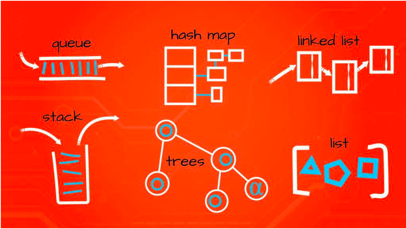
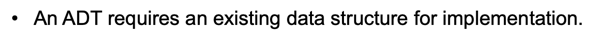

## Stack ADT


A stack is an ordered collection of items in which elements are added and removed from the top.

Stacks follow **LIFO (Last In, First Out)** order, like a stack of plates: the last item added is the first item removed.

The two main stack operations are:

- **Push:** Add an element to the top of the stack.
- **Pop:** Remove the most recently added element from the top of the stack.

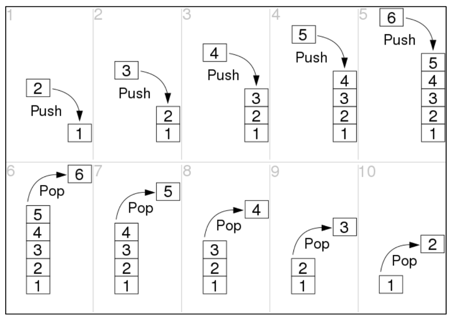

Implement the stack operations using extension functions. Each operation must preserve the original stack.

| Operation | Required behavior |
|---|---|
| `isEmpty()` | Return whether the stack is empty. |
| `push(value)` | Return a new stack with `value` on top. |
| `peek()` | Return the top value; throw an exception if empty. |
| `pop()` | Return the stack without its top; throw an exception if empty. |
| `size()` | Return the number of elements. |

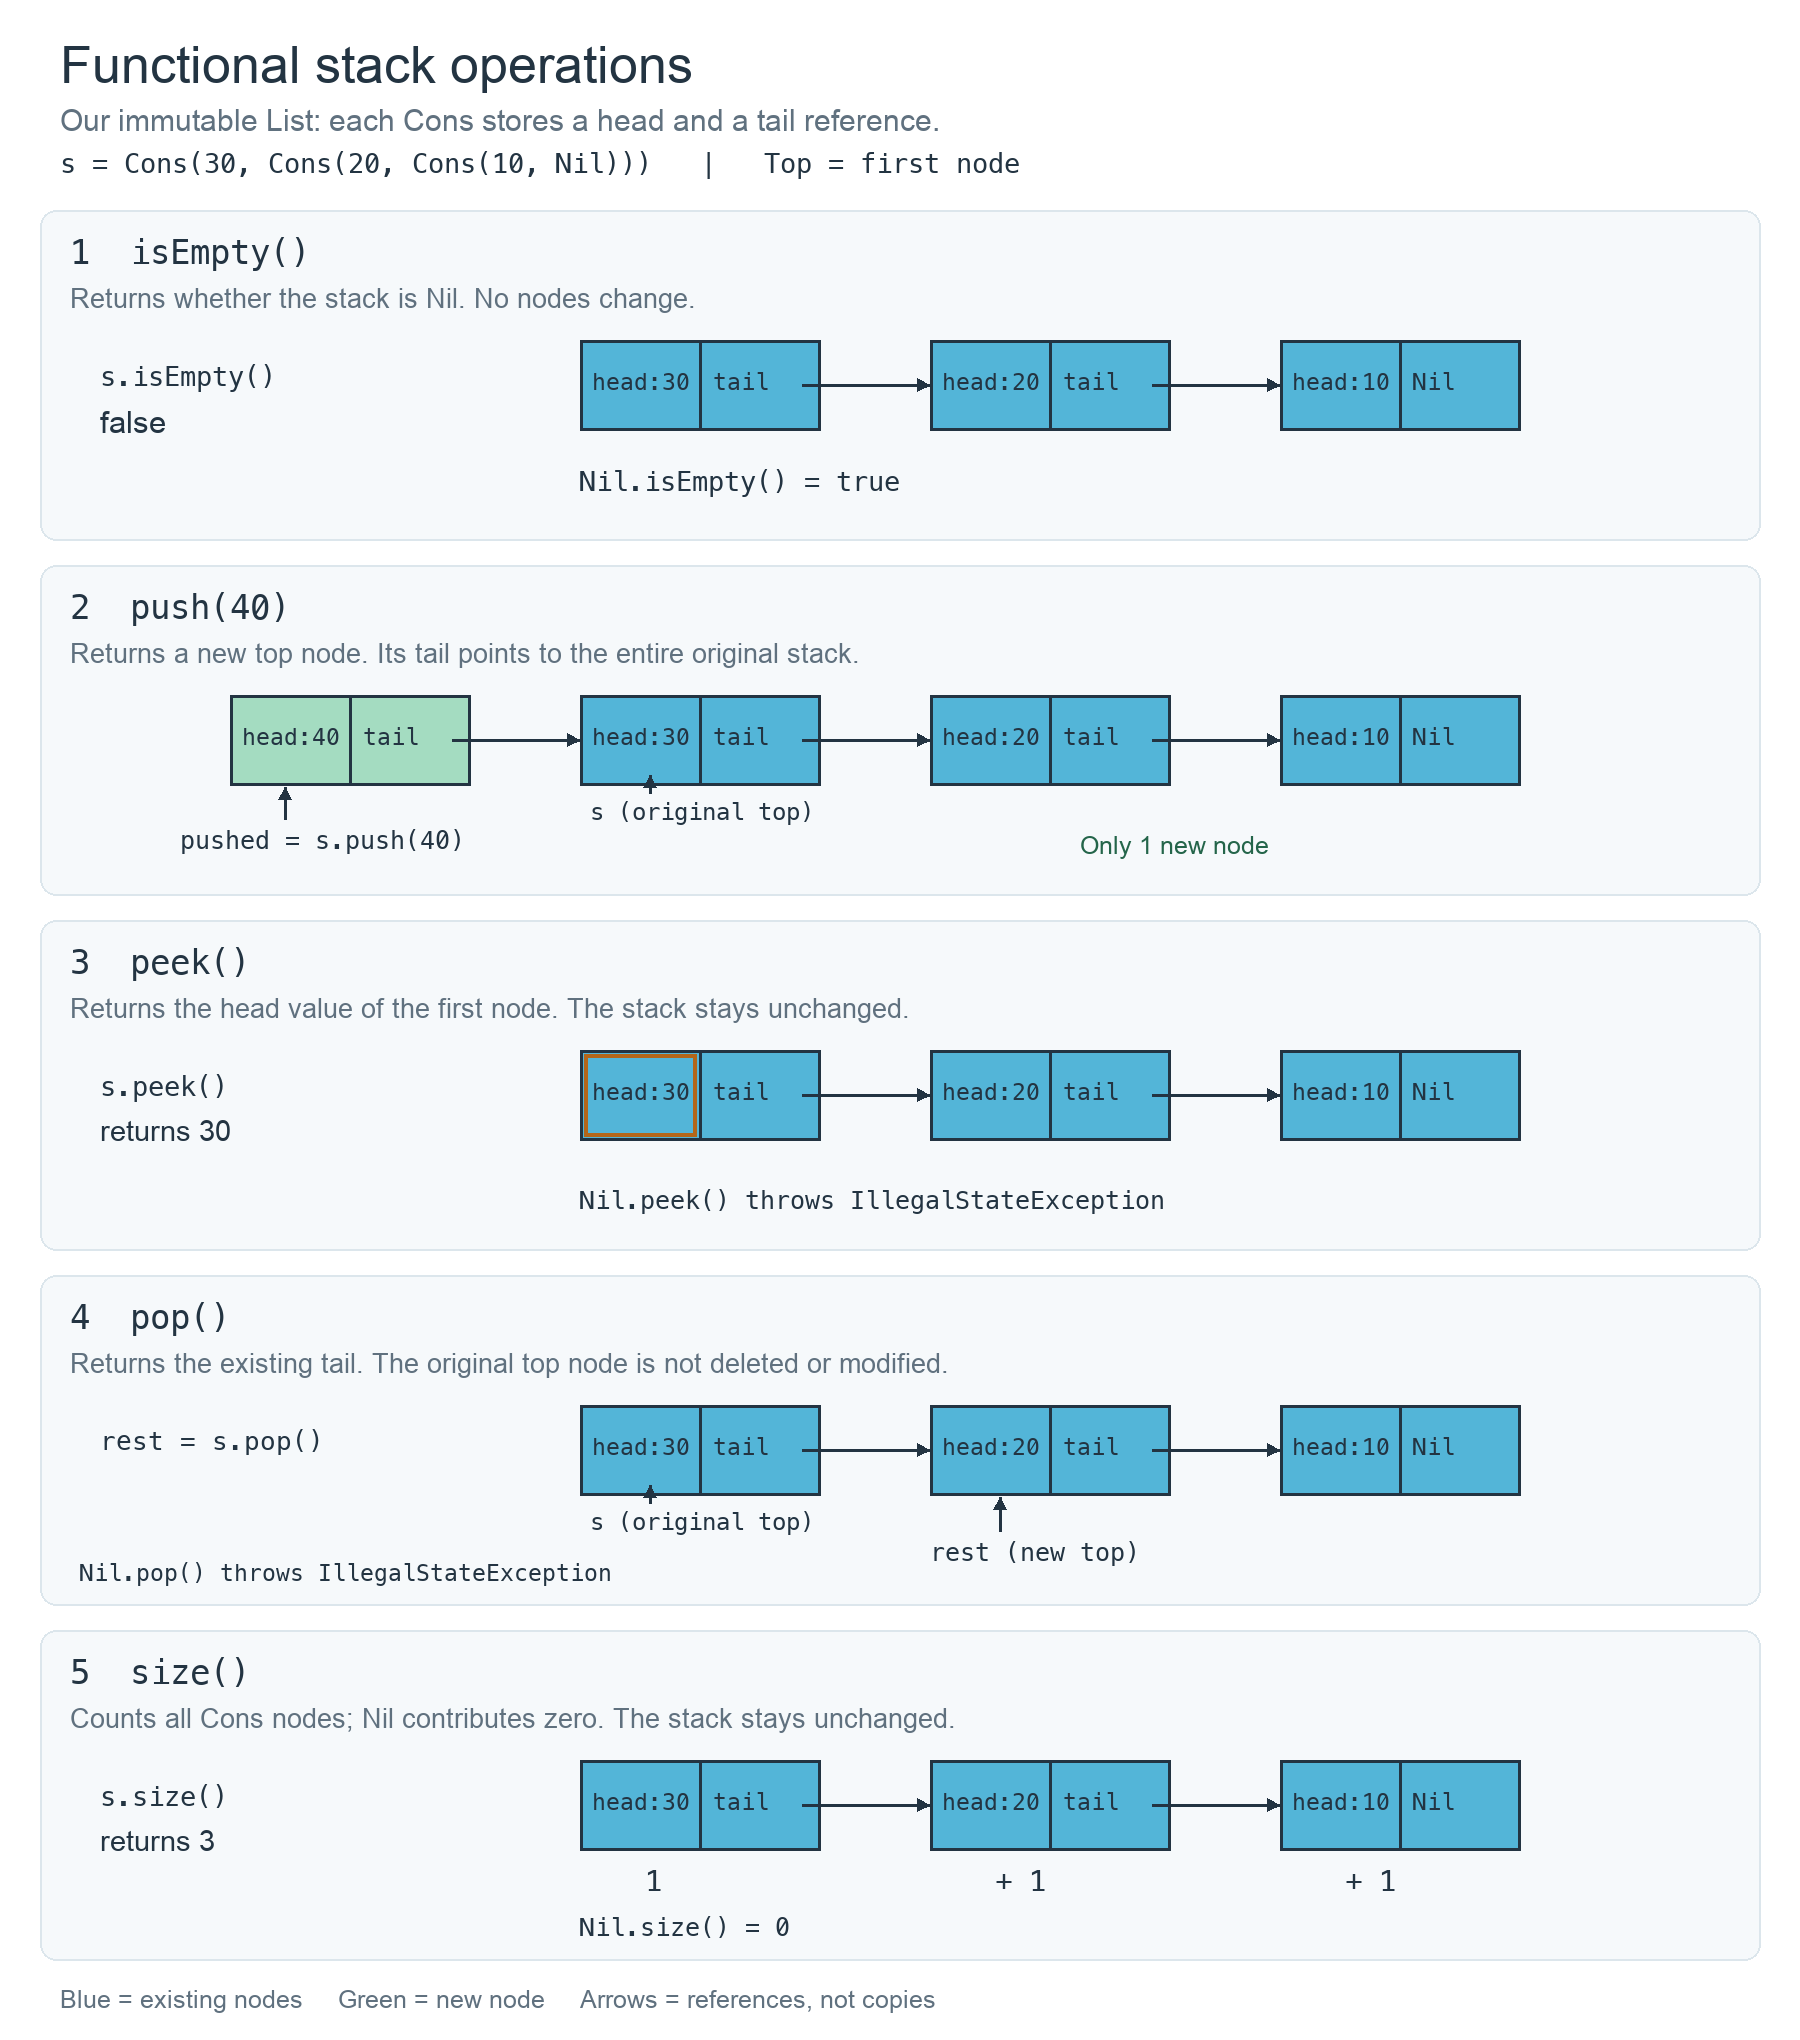

Student requirements:
- Use your existing functional List; do not use mutable collections.
- Keep items as a private val.
- Treat the list’s head as the stack’s top.
- Share existing list nodes when creating new stacks.
- Make peek() and pop() throw IllegalStateException on an empty stack.
Here, peek() returns the top value, while pop() returns the remaining stack.

In [161]:
class FunctionalStack<A>(
    private val items: List<A> = Nil
) {
    fun isEmpty(): Boolean =
        TODO("Check whether items is Nil")

    fun push(value: A): FunctionalStack<A> =
        TODO("Return FunctionalStack(Cons(value, items))")

    fun peek(): A =
        TODO("Return the head, or throw if empty")

    fun pop(): FunctionalStack<A> =
        TODO("Return a FunctionalStack containing the tail, or throw if empty")

    fun size(): Int =
        TODO("Reuse your length extension")
}

In [165]:
// Create an empty stack.
val emptyStack = FunctionalStack<Int>()
emptyStack

Line_163_jupyter$FunctionalStack@719332fd

### Empty


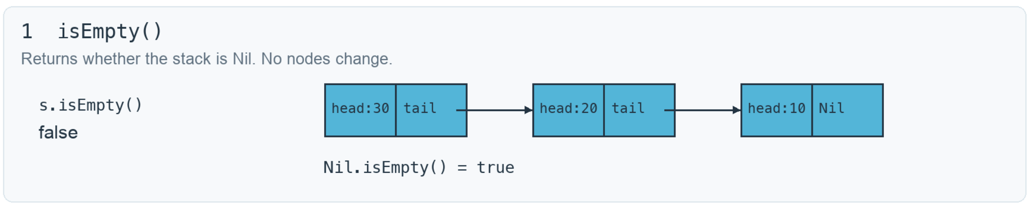

In [167]:
class FunctionalStack<A>(
    private val items: List<A> = Nil
) {
    fun isEmpty(): Boolean =
        items is Nil

    fun push(value: A): FunctionalStack<A> =
        TODO("Return FunctionalStack(Cons(value, items))")

    fun peek(): A =
        TODO("Return the head, or throw if empty")

    fun pop(): FunctionalStack<A> =
        TODO("Return a FunctionalStack containing the tail, or throw if empty")

    fun size(): Int =
        TODO("Reuse your length extension")
}

In [168]:
val emptyStack = FunctionalStack<Int>()
emptyStack.isEmpty()

true

### Push
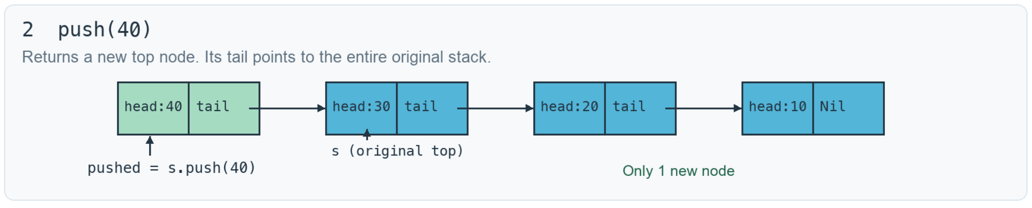

In [176]:
class FunctionalStack<A>(
    private val items: List<A> = Nil
) {
    fun isEmpty(): Boolean =
        items is Nil


    fun push(value: A): FunctionalStack<A> =
        FunctionalStack(Cons(value, items))

    fun peek(): A =
        TODO("Return the head, or throw if empty")

    fun pop(): FunctionalStack<A> =
        TODO("Return a FunctionalStack containing the tail, or throw if empty")

    fun size(): Int =
        TODO("Reuse your length extension")
}

In [180]:
val empty = FunctionalStack<Int>()
println(empty.isEmpty()) // true
val first = empty.push(10)

first


true


Line_178_jupyter$FunctionalStack@3f27fcc8